<a href="https://colab.research.google.com/github/tejasarulmani/Retail-Inventory-Optimization/blob/main/Retail_Inventory_Optimization_EOQ.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("marian447/retail-store-sales-transactions")

print("Path to dataset files:", path)

100%|██████████| 1.68M/1.68M [00:01<00:00, 1.73MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/marian447/retail-store-sales-transactions/versions/4


In [9]:
import pandas as pd
import os

# The 'path' variable from the previous cell contains the directory of the downloaded dataset.
# We determined earlier that 'scanner_data.csv' is the correct file.
data_file = os.path.join(path, 'scanner_data.csv')

# Load the CSV into a pandas DataFrame
df = pd.read_csv(data_file)

# Display the first 5 rows of the DataFrame
print("First 5 rows of the DataFrame:")
display(df.head())

# Print the DataFrame's information
print("\nDataFrame Information:")
df.info()

First 5 rows of the DataFrame:


,Unnamed: 0,Date,Customer_ID,Transaction_ID,SKU_Category,SKU,Quantity,Sales_Amount
0,1,02/01/2016,2547,1,X52,0EM7L,1.0,3.13
1,2,02/01/2016,822,2,2ML,68BRQ,1.0,5.46
2,3,02/01/2016,3686,3,0H2,CZUZX,1.0,6.35
3,4,02/01/2016,3719,4,0H2,549KK,1.0,5.59
4,5,02/01/2016,9200,5,0H2,K8EHH,1.0,6.88



DataFrame Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131706 entries, 0 to 131705
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   Unnamed: 0      131706 non-null  int64  
 1   Date            131706 non-null  object 
 2   Customer_ID     131706 non-null  int64  
 3   Transaction_ID  131706 non-null  int64  
 4   SKU_Category    131706 non-null  object 
 5   SKU             131706 non-null  object 
 6   Quantity        131706 non-null  float64
 7   Sales_Amount    131706 non-null  float64
dtypes: float64(2), int64(3), object(3)
memory usage: 8.0+ MB


In [12]:
# Rename columns to simpler names
df = df.rename(columns={
    'Unnamed: 0': 'Index',
    'Date': 'Date',
    'Customer_ID': 'Customer_ID',
    'Transaction_ID': 'Transaction_ID',
    'SKU_Category': 'Category_ID',
    'SKU': 'SKU_ID',
    'Quantity': 'Quantity',
    'Sales_Amount': 'Sales_Amount'
})

# Convert the 'Date' column to standard pandas datetime format, specifying dayfirst=True
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

# Create a new column called 'Unit_Price' by dividing Sales_Amount by Quantity
# Handle potential division by zero if Quantity can be 0 or NaN
df['Unit_Price'] = df['Sales_Amount'] / df['Quantity']

# Display the first 3 rows of the updated DataFrame
print("First 3 rows of the DataFrame after transformations:")
display(df.head(3))

First 3 rows of the DataFrame after transformations:


,Index,Date,Customer_ID,Transaction_ID,Category_ID,SKU_ID,Quantity,Sales_Amount,Unit_Price
0,1,2016-01-02,2547,1,X52,0EM7L,1.0,3.13,3.13
1,2,2016-01-02,822,2,2ML,68BRQ,1.0,5.46,5.46
2,3,2016-01-02,3686,3,0H2,CZUZX,1.0,6.35,6.35


In [13]:
# Group by SKU_ID and calculate total sales, then sort in descending order
sku_sales = df.groupby('SKU_ID')['Sales_Amount'].sum().sort_values(ascending=False).reset_index()

# Calculate the cumulative sum of sales
sku_sales['Cumulative_Sales'] = sku_sales['Sales_Amount'].cumsum()

# Calculate the cumulative percentage of total sales
sku_sales['Cumulative_Percentage'] = sku_sales['Cumulative_Sales'] / sku_sales['Sales_Amount'].sum()

# Filter for SKUs that make up the top 80% of sales
pareto_skus_df = sku_sales[sku_sales['Cumulative_Percentage'] <= 0.80]
pareto_skus = pareto_skus_df['SKU_ID'].tolist()

# Print the total number of SKUs and the number of SKUs in the 80% list
total_skus = df['SKU_ID'].nunique()
num_pareto_skus = len(pareto_skus)

print(f"Total number of unique SKUs: {total_skus}")
print(f"Number of SKUs making up the top 80% of sales: {num_pareto_skus}")

# Display the top SKU sales with cumulative percentages
print("\nSKU Sales with Cumulative Percentages (first 10 rows):")
display(sku_sales.head(10))

Total number of unique SKUs: 5242
Number of SKUs making up the top 80% of sales: 1136

SKU Sales with Cumulative Percentages (first 10 rows):


,SKU_ID,Sales_Amount,Cumulative_Sales,Cumulative_Percentage
0,3YDVF,29419.35,29419.35,0.018643
1,LJ26I,13571.45,42990.80,0.027243
2,IRQZ4,11681.63,54672.43,0.034646
3,DWJC4,10592.09,65264.52,0.041358
4,44RUE,8942.63,74207.15,0.047025
5,W6RZ8,8561.70,82768.85,0.052450
6,B87MU,8183.89,90952.74,0.057637
7,MYDIB,7933.95,98886.69,0.062664
8,BW8YX,7822.52,106709.21,0.067621
9,P35XJ,7759.64,114468.85,0.072539


In [14]:
df_top = df[df['SKU_ID'].isin(pareto_skus)]

print(f"Original DataFrame shape: {df.shape}")
print(f"Filtered DataFrame (df_top) shape: {df_top.shape}")
display(df_top.head())

Original DataFrame shape: (131706, 9)
Filtered DataFrame (df_top) shape: (92498, 9)


,Index,Date,Customer_ID,Transaction_ID,Category_ID,SKU_ID,Quantity,Sales_Amount,Unit_Price
1,2,2016-01-02,822,2,2ML,68BRQ,1.0,5.46,5.46
2,3,2016-01-02,3686,3,0H2,CZUZX,1.0,6.35,6.35
3,4,2016-01-02,3719,4,0H2,549KK,1.0,5.59,5.59
4,5,2016-01-02,9200,5,0H2,K8EHH,1.0,6.88,6.88
6,7,2016-01-02,1666,7,XG4,AHAE7,1.0,3.65,3.65


In [15]:
# Group df_top by SKU_ID and Date to find daily demand per item
daily_demand = df_top.groupby(['SKU_ID', 'Date'])['Quantity'].sum().reset_index()

# Group the daily demand data by SKU_ID to calculate EOQ inputs
eoq_inputs = daily_demand.groupby('SKU_ID')['Quantity'].agg(
    Annual_Demand=('sum'),
    Average_Daily_Demand=('mean'),
    Daily_Std_Dev=('std')
).reset_index()

# Display the first few rows of the eoq_inputs DataFrame
print("EOQ Inputs (first 5 rows):")
display(eoq_inputs.head())

EOQ Inputs (first 5 rows):


,SKU_ID,Annual_Demand,Average_Daily_Demand,Daily_Std_Dev
0,01L05,10.0,1.666667,0.516398
1,01V7M,45.0,1.125000,0.334932
2,07GHA,37.0,1.088235,0.378806
3,08F28,65.0,1.911765,0.865768
4,096VW,59.0,1.255319,0.487589


In [16]:
# Calculate the mean Unit_Price for each SKU_ID from df_top
avg_unit_price = df_top.groupby('SKU_ID')['Unit_Price'].mean().reset_index()
avg_unit_price.rename(columns={'Unit_Price': 'Average_Unit_Price'}, inplace=True)

# Merge the average unit price into the eoq_inputs DataFrame
eoq_inputs = pd.merge(eoq_inputs, avg_unit_price, on='SKU_ID', how='left')

# Add constant columns for EOQ parameters
eoq_inputs['Order_Cost'] = 50
eoq_inputs['Holding_Cost_Pct'] = 0.20
eoq_inputs['Lead_Time_Days'] = 14
eoq_inputs['Z_Score'] = 1.65 # Corresponds to a 95% service level for safety stock

print("EOQ Inputs DataFrame with pricing and business parameters (first 5 rows):")
display(eoq_inputs.head())

EOQ Inputs DataFrame with pricing and business parameters (first 5 rows):


,SKU_ID,Annual_Demand,Average_Daily_Demand,Daily_Std_Dev,Average_Unit_Price,Order_Cost,Holding_Cost_Pct,Lead_Time_Days,Z_Score
0,01L05,10.0,1.666667,0.516398,83.820000,50,0.2,14,1.65
1,01V7M,45.0,1.125000,0.334932,8.174186,50,0.2,14,1.65
2,07GHA,37.0,1.088235,0.378806,10.805143,50,0.2,14,1.65
3,08F28,65.0,1.911765,0.865768,9.583524,50,0.2,14,1.65
4,096VW,59.0,1.255319,0.487589,6.071176,50,0.2,14,1.65


In [17]:
import numpy as np

# Calculate Holding_Cost_Per_Unit
eoq_inputs['Holding_Cost_Per_Unit'] = eoq_inputs['Average_Unit_Price'] * eoq_inputs['Holding_Cost_Pct']

# Calculate EOQ
# Handle potential division by zero if Holding_Cost_Per_Unit is 0
eoq_inputs['EOQ'] = np.sqrt(
    (2 * eoq_inputs['Annual_Demand'] * eoq_inputs['Order_Cost']) /
    eoq_inputs['Holding_Cost_Per_Unit'].replace(0, np.nan) # Replace 0 with NaN to avoid division by zero
)

# Calculate Safety_Stock
# Handle potential NaN values from Daily_Std_Dev
eoq_inputs['Safety_Stock'] = (eoq_inputs['Z_Score'] * eoq_inputs['Daily_Std_Dev'] * np.sqrt(eoq_inputs['Lead_Time_Days']))

# Calculate Reorder_Point
eoq_inputs['Reorder_Point'] = (eoq_inputs['Average_Daily_Demand'] * eoq_inputs['Lead_Time_Days']) + eoq_inputs['Safety_Stock']

# Round EOQ, Safety_Stock, and Reorder_Point to the nearest whole number
eoq_inputs['EOQ'] = eoq_inputs['EOQ'].round().astype(pd.Int64Dtype())
eoq_inputs['Safety_Stock'] = eoq_inputs['Safety_Stock'].round().astype(pd.Int64Dtype())
eoq_inputs['Reorder_Point'] = eoq_inputs['Reorder_Point'].round().astype(pd.Int64Dtype())

print("EOQ Inputs DataFrame with calculated EOQ, Safety Stock, and Reorder Point (first 5 rows):")
display(eoq_inputs.head())

EOQ Inputs DataFrame with calculated EOQ, Safety Stock, and Reorder Point (first 5 rows):


,SKU_ID,Annual_Demand,Average_Daily_Demand,Daily_Std_Dev,Average_Unit_Price,Order_Cost,Holding_Cost_Pct,Lead_Time_Days,Z_Score,Holding_Cost_Per_Unit,EOQ,Safety_Stock,Reorder_Point
0,01L05,10.0,1.666667,0.516398,83.820000,50,0.2,14,1.65,16.764000,8,3,27
1,01V7M,45.0,1.125000,0.334932,8.174186,50,0.2,14,1.65,1.634837,52,2,18
2,07GHA,37.0,1.088235,0.378806,10.805143,50,0.2,14,1.65,2.161029,41,2,18
3,08F28,65.0,1.911765,0.865768,9.583524,50,0.2,14,1.65,1.916705,58,5,32
4,096VW,59.0,1.255319,0.487589,6.071176,50,0.2,14,1.65,1.214235,70,3,21


In [25]:
import numpy as np

# Calculate Current_Order_Quantity (assuming 12 orders per year for comparison)
eoq_inputs['Current_Order_Quantity'] = eoq_inputs['Annual_Demand'] / 12

# Calculate Total_Current_Cost
current_ordering_cost = (eoq_inputs['Annual_Demand'] / eoq_inputs['Current_Order_Quantity']) * eoq_inputs['Order_Cost']
current_holding_cost = (eoq_inputs['Current_Order_Quantity'] / 2) * eoq_inputs['Holding_Cost_Per_Unit']
eoq_inputs['Total_Current_Cost'] = current_ordering_cost + current_holding_cost

# Calculate Total_EOQ_Cost
# Handle potential division by zero if EOQ is 0, treating 0 EOQ as NaN for cost calculation
eoq_inputs['Total_EOQ_Cost'] = (
    (eoq_inputs['Annual_Demand'] / eoq_inputs['EOQ'].replace(0, np.nan)) * eoq_inputs['Order_Cost'] +
    (eoq_inputs['EOQ'].replace(0, np.nan) / 2) * eoq_inputs['Holding_Cost_Per_Unit']
)

# Calculate Cost_Savings
eoq_inputs['Cost_Savings'] = eoq_inputs['Total_Current_Cost'] - eoq_inputs['Total_EOQ_Cost']

# Calculate Savings_Percentage
eoq_inputs['Savings_Percentage'] = (eoq_inputs['Cost_Savings'] / eoq_inputs['Total_Current_Cost']) * 100

# Sort the DataFrame by 'Cost_Savings' in descending order
sorted_eoq_inputs = eoq_inputs.sort_values(by='Cost_Savings', ascending=False)

# Grab the top 10 rows
top_10_savings = sorted_eoq_inputs.head(10)

# Apply background gradient to 'Cost_Savings' and 'Savings_Percentage' columns
styled_df = top_10_savings.style.background_gradient(cmap='Greens', subset=['Cost_Savings', 'Savings_Percentage'])

print("Top 10 SKUs by Cost Savings:")
display(styled_df)

Top 10 SKUs by Cost Savings:


,SKU_ID,Annual_Demand,Average_Daily_Demand,Daily_Std_Dev,Average_Unit_Price,Order_Cost,Holding_Cost_Pct,Lead_Time_Days,Z_Score,Holding_Cost_Per_Unit,EOQ,Safety_Stock,Reorder_Point,Current_Order_Quantity,Total_Current_Cost,Total_EOQ_Cost,Cost_Savings,Savings_Percentage
767,N25TU,23.000000,1.000000,0.000000,13.296087,50,0.200000,14,1.650000,2.659217,29,0,14,1.916667,602.548417,78.213825,524.334592,87.019495
462,DYMFI,129.000000,2.224138,0.974105,2.371164,50,0.200000,14,1.650000,0.474233,165,6,37,10.750000,602.549001,78.215115,524.333886,87.019294
36,1CJ28,103.000000,2.340909,1.379976,2.970595,50,0.200000,14,1.650000,0.594119,132,9,41,8.583333,602.549761,78.227009,524.322752,87.017336
1099,YS9IS,39.000000,1.026316,0.162221,7.850000,50,0.200000,14,1.650000,1.570000,50,1,15,3.250000,602.551250,78.250000,524.301250,87.013553
1096,YR1OH,24.000000,1.043478,0.208514,12.792500,50,0.200000,14,1.650000,2.558500,31,1,16,2.000000,602.558500,78.366427,524.192073,86.994387
14,0POSZ,8.000000,1.000000,0.000000,38.380000,50,0.200000,14,1.650000,7.676000,10,0,14,0.666667,602.558667,78.380000,524.178667,86.992138
442,DE1MW,14.000000,1.000000,0.000000,21.950000,50,0.200000,14,1.650000,4.390000,18,0,14,1.166667,602.560833,78.398889,524.161944,86.989050
575,H8P2L,1118.000000,43.000000,26.814921,0.274927,50,0.200000,14,1.650000,0.054985,1426,166,768,93.166667,602.561405,78.405176,524.156229,86.988019
854,Q2G19,14.000000,1.076923,0.277350,21.957857,50,0.200000,14,1.650000,4.391571,18,2,17,1.166667,602.561750,78.413032,524.148718,86.986723
317,9I5KY,39.000000,1.500000,0.648074,7.891358,50,0.200000,14,1.650000,1.578272,50,4,25,3.250000,602.564691,78.456790,524.107901,86.979524


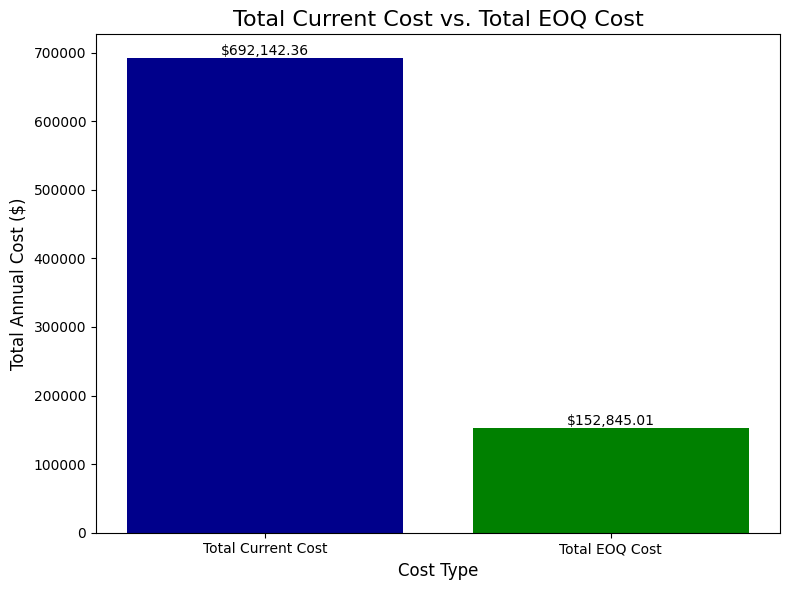


--- Financial Impact Summary ---
Total Projected Annual Savings: $539,297.35
Percentage Savings: 77.92%


In [26]:
import matplotlib.pyplot as plt
import pandas as pd

# Calculate the grand totals (re-calculating to ensure they are current within this cell's execution context)
grand_total_current_cost = eoq_inputs['Total_Current_Cost'].sum()
grand_total_eoq_cost = eoq_inputs['Total_EOQ_Cost'].sum()
grand_total_cost_savings = grand_total_current_cost - grand_total_eoq_cost

# Create a DataFrame for plotting
financial_summary_totals = pd.DataFrame({
    'Cost Type': ['Total Current Cost', 'Total EOQ Cost'],
    'Amount': [grand_total_current_cost, grand_total_eoq_cost]
})

# Define custom colors
colors = ['darkblue', 'green']

# Create the bar chart
fig, ax = plt.subplots(figsize=(8, 6))
ax.bar(financial_summary_totals['Cost Type'], financial_summary_totals['Amount'], color=colors)

# Add title and labels
ax.set_title('Total Current Cost vs. Total EOQ Cost', fontsize=16)
ax.set_xlabel('Cost Type', fontsize=12)
ax.set_ylabel('Total Annual Cost ($)', fontsize=12)

# Display the exact dollar amount on top of each bar
for p in ax.patches:
    ax.annotate(f'${p.get_height():,.2f}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', fontsize=10, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.tight_layout()
plt.show()

# Calculate percentage savings
percentage_savings = (grand_total_cost_savings / grand_total_current_cost) * 100 if grand_total_current_cost != 0 else 0

# Print summary statement
print("\n--- Financial Impact Summary ---")
print(f"Total Projected Annual Savings: ${grand_total_cost_savings:,.2f}")
print(f"Percentage Savings: {percentage_savings:.2f}%")
